In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

In [4]:
# 1. LOAD DATASETS
crop_rec_df = pd.read_csv("Crop_recommendation.csv")  # from Crop Recommendation Dataset
crop_prod_df = pd.read_csv("crop_production.csv")      # from Crop Production in India Dataset

In [13]:
# 2. EXPLORE CROP RECOMMENDATION DATA
print("Crop Recommendation Dataset:")
print(crop_rec_df.tail(5))
print(crop_rec_df["label"].value_counts())

Crop Recommendation Dataset:
        N   P   K  temperature   humidity        ph    rainfall   label
2195  107  34  32    26.774637  66.413269  6.780064  177.774507  coffee
2196   99  15  27    27.417112  56.636362  6.086922  127.924610  coffee
2197  118  33  30    24.131797  67.225123  6.362608  173.322839  coffee
2198  117  32  34    26.272418  52.127394  6.758793  127.175293  coffee
2199  104  18  30    23.603016  60.396475  6.779833  140.937041  coffee
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: label, dtype: int64


In [8]:
# 3. TRAIN ML MODEL FOR CROP RECOMMENDATION
X = crop_rec_df.drop("label", axis=1)
y = crop_rec_df["label"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [11]:
y_pred = model.predict(X_test)
print("Model Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9931818181818182
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        23
      banana       1.00      1.00      1.00        21
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        26
     coconut       1.00      1.00      1.00        27
      coffee       1.00      1.00      1.00        17
      cotton       1.00      1.00      1.00        17
      grapes       1.00      1.00      1.00        14
        jute       0.92      1.00      0.96        23
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.92      1.00      0.96        11
       maize       1.00      1.00      1.00        21
       mango       1.00      1.00      1.00        19
   mothbeans       1.00      0.96      0.98        24
    mungbean       1.00      1.00      1.00        19
   muskmelon       1.00      1.00      1.00        17
      orange       1.00      1.00      1.00   

In [12]:
# 4. SAMPLE CROP RECOMMENDATION
sample_input = pd.DataFrame({
    'N': [35],
    'P': [10],
    'K': [95],
    'temperature': [29],
    'humidity': [60],
    'ph': [7],
    'rainfall': [50]
})
predicted_crop = model.predict(sample_input)
print("Recommended Crop:", predicted_crop[0])


Recommended Crop: mango


In [14]:
# 5. EXPLORE PRODUCTION DATA (YIELD ANALYSIS)
crop_prod_df = crop_prod_df.dropna()
crop_prod_df["Yield"] = crop_prod_df["Production"] / crop_prod_df["Area"]
avg_yield = crop_prod_df.groupby("Crop")["Yield"].mean().sort_values(ascending=False)
print("Top 10 Crops by Average Yield:")
print(avg_yield.head(10))

Top 10 Crops by Average Yield:
Crop
Coconut      4040.403568
Sugarcane     195.003397
Papaya         28.659374
Banana         27.064755
Grapes         19.229891
Tapioca        18.773412
Pineapple      13.996944
Potato         12.867025
Cabbage        11.920462
Onion          11.855243
Name: Yield, dtype: float64


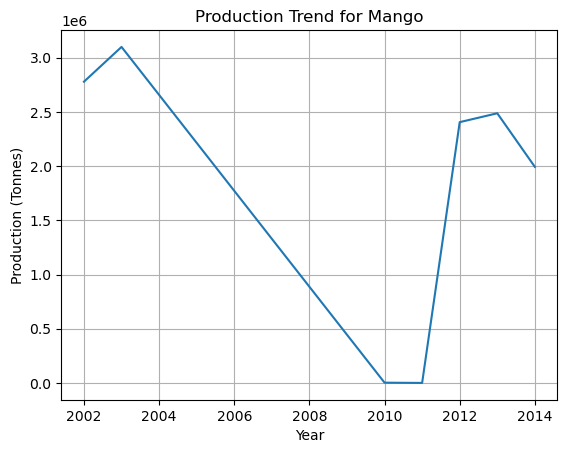

In [16]:
# 6. PLOT PRODUCTION TRENDS FOR A CROP
def plot_crop_trend(crop_name):
    crop_data = crop_prod_df[crop_prod_df["Crop"] == crop_name]
    trend = crop_data.groupby("Crop_Year")["Production"].sum()
    trend.plot(kind="line", title=f"Production Trend for {crop_name}", ylabel="Production (Tonnes)", xlabel="Year")
    plt.grid(True)
    plt.show()

plot_crop_trend("Mango")  # Example

In [17]:
# 7. INTEGRATE RECOMMENDATION + PROFITABILITY
recommended_crop = predicted_crop[0]
if recommended_crop in avg_yield:
    print(f"Estimated Yield for {recommended_crop}: {avg_yield[recommended_crop]:.2f} Tonnes/ha")
else:
    print(f"No yield data available for {recommended_crop}")


No yield data available for mango
